### 1️⃣ Selecting Columns - select()
Use Case: Extract specific columns from a DataFrame.

In [ ]:
# syntax
df.select("column_name")
df.select("col1", "col2")

In [ ]:
pip install pyspark

In [ ]:
import pyspark

In [ ]:
# example
from pyspark.sql import SparkSession

spark = SparkSession.builder.appName("DataFrameOps").getOrCreate()

In [ ]:
data = [(1, "Alice", 25), (2, "Bob", 30), (3, "Charlie", 35)]

columns = ["id", "name", "age"]

In [ ]:
df = spark.createDataFrame(data, columns)

In [ ]:
df.show()

+---+-------+---+
| id|   name|age|
+---+-------+---+
|  1|  Alice| 25|
|  2|    Bob| 30|
|  3|Charlie| 35|
+---+-------+---+



In [ ]:
df.select('name').show()

+-------+
|   name|
+-------+
|  Alice|
|    Bob|
|Charlie|
+-------+



In [ ]:
df.select('id','name').show()

+---+-------+
| id|   name|
+---+-------+
|  1|  Alice|
|  2|    Bob|
|  3|Charlie|
+---+-------+



✅ Key Takeaways:

select() is used for fetching specific columns.

Multiple columns can be selected by passing them as separate arguments.

### 2️⃣ Filtering Data - filter() & where()
Use Case: Filter rows based on conditions.

In [ ]:
# synatx
df.filter(df.column_name == "value")

df.where(df.column_name > value)

In [ ]:
df.name
col("name'")

In [ ]:
df.filter(df.name =='Bob').show()

+---+----+---+
| id|name|age|
+---+----+---+
|  2| Bob| 30|
+---+----+---+



In [ ]:
df.filter(df.age == 35).show()

+---+-------+---+
| id|   name|age|
+---+-------+---+
|  3|Charlie| 35|
+---+-------+---+



In [ ]:
df.where(df.name =='Alice').show()

+---+-----+---+
| id| name|age|
+---+-----+---+
|  1|Alice| 25|
+---+-----+---+



In [ ]:
df.where(df.age == 35).show()

+---+-------+---+
| id|   name|age|
+---+-------+---+
|  3|Charlie| 35|
+---+-------+---+



### use filetrr with multiple conditions

In [ ]:
data = [
    (1, "Alice", "HR", 5000),
    (2, "Bob", "IT", 7000),
    (3, "Charlie", "HR", 6000),
    (4, "David", "IT", 8000),
    (5, "Eve", "Finance", 7500)
]

df = spark.createDataFrame(data, ["id", "name", "department", "salary"])
df.show()

+---+-------+----------+------+
| id|   name|department|salary|
+---+-------+----------+------+
|  1|  Alice|        HR|  5000|
|  2|    Bob|        IT|  7000|
|  3|Charlie|        HR|  6000|
|  4|  David|        IT|  8000|
|  5|    Eve|   Finance|  7500|
+---+-------+----------+------+



In [ ]:
df.filter((df.salary > 7000) & (df.department == 'IT')).show()

+---+-----+----------+------+
| id| name|department|salary|
+---+-----+----------+------+
|  4|David|        IT|  8000|
+---+-----+----------+------+



In [ ]:
df.filter((df.salary > 5000) & (df.department == "XYZ")).show()

+---+----+----------+------+
| id|name|department|salary|
+---+----+----------+------+
+---+----+----------+------+



✅ Key Takeaways:

filter() and where() work the same way.

Conditions use ==, >, <, >=, <=, !=.

Multiple conditions can be combined using & (AND) or | (OR).

### 3️⃣ Grouping and Aggregation - groupBy() & agg()
Use Case: Perform aggregations like sum, count, average, etc.

In [ ]:
# syntax
df.groupBy("column").agg(functions)

In [ ]:
# example
from pyspark.sql.functions import sum, avg, count

df.groupBy("age").agg(count("*").alias("count")).show()

✅ Key Takeaways:

groupBy() groups the data based on a column.

agg() applies aggregation functions (sum(), avg(), count(), etc.).

alias() renames the column for clarity.

### 4️⃣ Removing Duplicates - distinct() & dropDuplicates()
Use Case: Remove duplicate rows from DataFrame.

In [ ]:
# syntax
df.distinct()
df.dropDuplicates()

In [ ]:
data_dup = [(1, "Alice", 25), (2, "Bob", 30), (1, "Alice", 25)]

df = spark.createDataFrame(data_dup, ["id", "name", "age"])

In [ ]:
df.show()

+---+-----+---+
| id| name|age|
+---+-----+---+
|  1|Alice| 25|
|  2|  Bob| 30|
|  1|Alice| 25|
+---+-----+---+



In [ ]:
df2 = df.dropDuplicates()
df2.show()

+---+-----+---+
| id| name|age|
+---+-----+---+
|  1|Alice| 25|
|  2|  Bob| 30|
+---+-----+---+



In [ ]:
df3 = df.dropDuplicates(['name'])

In [ ]:
df.dropDuplicates(['name','age'])

In [ ]:
id name dept salary

1 bob IT 3000
2 alice CS 6000
3 bob IT 4000
2 alice CS 6000
4 Rohit Mech 9000

1 bob IT 3000
3 bob IT 4000

df.dropDuplicates(['name','age'])

In [ ]:
df.show()

+---+-----+---+
| id| name|age|
+---+-----+---+
|  1|Alice| 25|
|  2|  Bob| 30|
|  1|Alice| 25|
+---+-----+---+



In [ ]:
df.distinct().show()

+---+-----+---+
| id| name|age|
+---+-----+---+
|  1|Alice| 25|
|  2|  Bob| 30|
+---+-----+---+



In [ ]:
data = [
    (1, "Alice", "HR", 5000),
    (2, "Bob", "IT", 7000),
    (1, "Alice", "HR", 5000)  # Duplicate row
]

df = spark.createDataFrame(data, ["id", "name", "department", "salary"])

df.show()


+---+-----+----------+------+
| id| name|department|salary|
+---+-----+----------+------+
|  1|Alice|        HR|  5000|
|  2|  Bob|        IT|  7000|
|  1|Alice|        HR|  5000|
+---+-----+----------+------+



In [ ]:
df.dropDuplicates().show()

+---+-----+----------+------+
| id| name|department|salary|
+---+-----+----------+------+
|  1|Alice|        HR|  5000|
|  2|  Bob|        IT|  7000|
+---+-----+----------+------+



In [ ]:
df.show()

+---+-----+----------+------+
| id| name|department|salary|
+---+-----+----------+------+
|  1|Alice|        HR|  5000|
|  2|  Bob|        IT|  7000|
|  1|Alice|        HR|  5000|
+---+-----+----------+------+



In [ ]:
df2 = df.distinct()
df2.show()

+---+-----+----------+------+
| id| name|department|salary|
+---+-----+----------+------+
|  1|Alice|        HR|  5000|
|  2|  Bob|        IT|  7000|
+---+-----+----------+------+



In [ ]:
df.show()

+---+-----+----------+------+
| id| name|department|salary|
+---+-----+----------+------+
|  1|Alice|        HR|  5000|
|  2|  Bob|        IT|  7000|
|  1|Alice|        HR|  5000|
+---+-----+----------+------+



In [ ]:
df3 = df.dropDuplicates()
#df3.show()
df.show()

+---+-----+----------+------+
| id| name|department|salary|
+---+-----+----------+------+
|  1|Alice|        HR|  5000|
|  2|  Bob|        IT|  7000|
|  1|Alice|        HR|  5000|
+---+-----+----------+------+



In [ ]:
df.show()

+---+-----+----------+------+
| id| name|department|salary|
+---+-----+----------+------+
|  1|Alice|        HR|  5000|
|  2|  Bob|        IT|  7000|
|  1|Alice|        HR|  5000|
+---+-----+----------+------+



In [ ]:
df.distinct().show()

+---+-----+----------+------+
| id| name|department|salary|
+---+-----+----------+------+
|  1|Alice|        HR|  5000|
|  2|  Bob|        IT|  7000|
+---+-----+----------+------+



In [ ]:
df.show()

+---+-----+----------+------+
| id| name|department|salary|
+---+-----+----------+------+
|  1|Alice|        HR|  5000|
|  2|  Bob|        IT|  7000|
|  1|Alice|        HR|  5000|
+---+-----+----------+------+



In [ ]:
df2 = df.distinct()

In [ ]:
df2.show()

+---+-----+----------+------+
| id| name|department|salary|
+---+-----+----------+------+
|  1|Alice|        HR|  5000|
|  2|  Bob|        IT|  7000|
+---+-----+----------+------+



✅ Key Takeaways:

distinct() removes all duplicate rows.

dropDuplicates(["col1", "col2"]) removes duplicates based on specific columns.

### 5️⃣ Modifying Columns - withColumn() & withColumnRenamed()
Use Case:

withColumn() adds or modifies a column.

withColumnRenamed() renames a column.

In [ ]:
from pyspark.sql.functions import lit

df.withColumn("new_col", lit("default_value")).show()

df.withColumnRenamed("age", "years").show()


✅ Key Takeaways:

withColumn() is used to add or modify an existing column.

lit(value) assigns a constant value to the new column.

withColumnRenamed() only renames columns.

# Finding Null Values in PySpark DataFrame

When working with real-world data, it's important to check for missing values (null values) in a DataFrame.

 PySpark provides multiple ways to find and handle null values.

### 1️⃣ Checking for Null Values in a Column (isNull())

This method helps identify rows where a specific column has null values.

In [ ]:
from pyspark.sql.functions import *

In [ ]:
# Sample DataFrame
data = [("Amit", None, 50000), ("Priya", 28, None), ("Raj", 30, 70000), ("Sara", None, None)]
df = spark.createDataFrame(data, ["Name", "Age", "Salary"])
df.show()

+-----+----+------+
| Name| Age|Salary|
+-----+----+------+
| Amit|NULL| 50000|
|Priya|  28|  NULL|
|  Raj|  30| 70000|
| Sara|NULL|  NULL|
+-----+----+------+



In [ ]:
# Example 1: Find rows where Age is null
df.filter(df.Age.isNull()).show()
df.filter(col('Age').isNull()).show()

+----+----+------+
|Name| Age|Salary|
+----+----+------+
|Amit|NULL| 50000|
|Sara|NULL|  NULL|
+----+----+------+



In [ ]:
df.filter(col('Salary').isNull()).show()

+-----+----+------+
| Name| Age|Salary|
+-----+----+------+
|Priya|  28|  NULL|
| Sara|NULL|  NULL|
+-----+----+------+



In [ ]:

# Example 2: Find rows where Salary is null
df.filter(col("Salary").isNull()).show()


+-----+----+------+
| Name| Age|Salary|
+-----+----+------+
|Priya|  28|  NULL|
| Sara|NULL|  NULL|
+-----+----+------+



In [ ]:
# Example 3:
df.filter((df.Name.isNull()) & (df.Salary.isNull()) ).show()

+----+---+------+
|Name|Age|Salary|
+----+---+------+
+----+---+------+



In [ ]:
df.filter((df.Name.isNull()) | (df.Salary.isNull()) ).show()

+-----+----+------+
| Name| Age|Salary|
+-----+----+------+
|Priya|  28|  NULL|
| Sara|NULL|  NULL|
+-----+----+------+



In [ ]:
# Example 4: using pipe symbol
df.filter(col('Name').isNull() | col('Age').isNull()).show()

# In this example, we are filtering rows where either the Name is null or the Age is null.
# The | symbol here is a logical OR, used to combine both conditions.

In [ ]:
# Eaxmple 5:
df.filter(col('Age').isNull() & col('Salary').isNull()).show()

+----+----+------+
|Name| Age|Salary|
+----+----+------+
|Sara|NULL|  NULL|
+----+----+------+



In [ ]:
# Example 6:
df.filter(col('Name').isNull() & col('Age').isNull() & col('Salary').isNull()).show()


+----+---+------+
|Name|Age|Salary|
+----+---+------+
+----+---+------+



In [10]:
df.show()

+-----+----+------+
| Name| Age|Salary|
+-----+----+------+
| Amit|NULL| 50000|
|Priya|  28|  NULL|
|  Raj|  30| 70000|
| Sara|NULL|  NULL|
+-----+----+------+



🔹 Explanation: isNull() checks for NULL values in a specific column.

In [ ]:
#🔹 Explanation: isNull() checks for NULL values in a specific column.

### 2️⃣ Checking for Non-Null Values (isNotNull())

This method helps find rows where a column has non-null values.

In [ ]:
#Syntax
df.filter(col('column').isNotNull())

In [12]:
df.filter(col('Age').isNotNull()).show()

+-----+---+------+
| Name|Age|Salary|
+-----+---+------+
|Priya| 28|  NULL|
|  Raj| 30| 70000|
+-----+---+------+



In [ ]:
# Example 2: Find rows where Salary is NOT null
df.filter(col("Salary").isNotNull()).show()

+----+----+------+
|Name| Age|Salary|
+----+----+------+
|Amit|NULL| 50000|
| Raj|  30| 70000|
+----+----+------+



🔹 Explanation: isNotNull() filters out null values and returns only non-null records.

### 3️⃣ Counting Null Values in Each Column (agg())

This method calculates the total number of null values in each column.

In [14]:
from pyspark.sql.functions import sum

# Example 1: Count null values in each column
df.select([sum(col(c).isNull().cast('int')).alias(c) for c in df.columns]).show()


+----+---+------+
|Name|Age|Salary|
+----+---+------+
|   0|  2|     2|
+----+---+------+



In [15]:
# using count
df.select([count(when(col(c).isNull(), c)).alias(c) for c in df.columns]).show()

+----+---+------+
|Name|Age|Salary|
+----+---+------+
|   0|  2|     2|
+----+---+------+



In [ ]:
df.select([count(when(col(c).isNull(), c)).alias(c) for c in df.columns ]).show()

+----+---+------+
|Name|Age|Salary|
+----+---+------+
|   0|  2|     2|
+----+---+------+



In [ ]:
df.columns

['Name', 'Age', 'Salary']

### 6️⃣ Handling Null Values - dropna(), fillna()
Use Case: Handle missing values in DataFrame.

In [ ]:
# syntax
df.dropna()
df.fillna(value, subset=["column_name"] )

In [16]:
data_null = [(1, "Alice", None), (2, "Bob", 30), (3, None, 35)]
df_null = spark.createDataFrame(data_null, ["id", "name", "age"])

In [17]:
df_null.show()

+---+-----+----+
| id| name| age|
+---+-----+----+
|  1|Alice|NULL|
|  2|  Bob|  30|
|  3| NULL|  35|
+---+-----+----+



In [18]:
df_null.dropna().show()

+---+----+---+
| id|name|age|
+---+----+---+
|  2| Bob| 30|
+---+----+---+



In [ ]:
df_null.show()

+---+-----+----+
| id| name| age|
+---+-----+----+
|  1|Alice|NULL|
|  2|  Bob|  30|
|  3| NULL|  35|
+---+-----+----+



In [19]:
df_null.show()

+---+-----+----+
| id| name| age|
+---+-----+----+
|  1|Alice|NULL|
|  2|  Bob|  30|
|  3| NULL|  35|
+---+-----+----+



In [20]:
df_null.dropna(how='all').show()

+---+-----+----+
| id| name| age|
+---+-----+----+
|  1|Alice|NULL|
|  2|  Bob|  30|
|  3| NULL|  35|
+---+-----+----+



In [21]:
df_null.dropna(subset=['name','age']).show()

+---+----+---+
| id|name|age|
+---+----+---+
|  2| Bob| 30|
+---+----+---+



1️⃣ dropna() – Removing Rows with NULLs

In [ ]:
df.dropna(how='any')    # Drops rows if any column has NULL  #dropna()
df.dropna(how='all')    # Drops rows only if all columns are NULL
df.dropna(subset=['col1', 'col2'])  # Drops rows if 'col1' or 'col2' has NULL


In [ ]:
from pyspark.sql import SparkSession

spark = SparkSession.builder.appName("DropNA_Example").getOrCreate()

data = [
    (1, "Alice", None),
    (2, "Bob", "HR"),
    (3, None, "IT"),
    (None, None, None),
    (5, "Eve", "Finance"),
]

columns = ["id", "name", "department"]
df = spark.createDataFrame(data, columns)

print("Original DataFrame:")
df.show()


Original DataFrame:
+----+-----+----------+
|  id| name|department|
+----+-----+----------+
|   1|Alice|      NULL|
|   2|  Bob|        HR|
|   3| NULL|        IT|
|NULL| NULL|      NULL|
|   5|  Eve|   Finance|
+----+-----+----------+



3️⃣ Using dropna()

how='any' → Drops rows if any column has NULL

In [ ]:
# Drops rows 1, 3, and 4 because they have at least one NULL.
df.dropna(how="any").show()


+---+----+----------+
| id|name|department|
+---+----+----------+
|  2| Bob|        HR|
|  5| Eve|   Finance|
+---+----+----------+



how='all' → Drops rows only if all columns are NULL

In [ ]:
df.dropna(how="all").show()
# Drops only row 4, because it has all NULL values.

+---+-----+----------+
| id| name|department|
+---+-----+----------+
|  1|Alice|      NULL|
|  2|  Bob|        HR|
|  3| NULL|        IT|
|  5|  Eve|   Finance|
+---+-----+----------+



subset=['col1', 'col2'] → Drops rows if specific columns have NULL

In [ ]:
df = spark.read.csv('file_path')

In [ ]:
df.show()

In [ ]:
df.describe()

In [ ]:
df.columns

In [ ]:
df.show()

+----+-----+----------+
|  id| name|department|
+----+-----+----------+
|   1|Alice|      NULL|
|   2|  Bob|        HR|
|   3| NULL|        IT|
|NULL| NULL|      NULL|
|   5|  Eve|   Finance|
+----+-----+----------+



In [ ]:
df.dropna(subset=["name"]).show()
# Drops rows where name is NULL (rows 3 and 4).

+---+-----+----------+
| id| name|department|
+---+-----+----------+
|  1|Alice|      NULL|
|  2|  Bob|        HR|
|  5|  Eve|   Finance|
+---+-----+----------+



In [ ]:
df.show()

+----+-----+----------+
|  id| name|department|
+----+-----+----------+
|   1|Alice|      NULL|
|   2|  Bob|        HR|
|   3| NULL|        IT|
|NULL| NULL|      NULL|
|   5|  Eve|   Finance|
+----+-----+----------+



In [ ]:
df.dropna(subset=["name","department"]).show()
# Drops rows where name and department is NULL

+---+----+----------+
| id|name|department|
+---+----+----------+
|  2| Bob|        HR|
|  5| Eve|   Finance|
+---+----+----------+



In [ ]:
df_null.fillna("Unknown", subset=["name"]).show()  # Replaces null in 'name'

df.fillna({"name": "Unknown"})

+---+-------+----+
| id|   name| age|
+---+-------+----+
|  1|  Alice|NULL|
|  2|    Bob|  30|
|  3|Unknown|  35|
+---+-------+----+



In [ ]:
# example
data_null = [(1, "Alice", None), (2, "Bob", 30), (3, None, 35)]
df_null = spark.createDataFrame(data_null, ["id", "name", "age"])

df_null.dropna().show()  # Removes rows with nulls
df_null.fillna("Unknown", subset=["name"]).show()  # Replaces null in 'name'


+---+----+---+
| id|name|age|
+---+----+---+
|  2| Bob| 30|
+---+----+---+

+---+-------+----+
| id|   name| age|
+---+-------+----+
|  1|  Alice|NULL|
|  2|    Bob|  30|
|  3|Unknown|  35|
+---+-------+----+



How to replace missing values column-wise.

In [22]:
data = [
    (1, "Alice", None, 5000),
    (2, "Bob", "IT", None),
    (3, None, "HR", 6000)
]

df = spark.createDataFrame(data, ["id", "name", "department", "salary"])

In [23]:
df.show()

+---+-----+----------+------+
| id| name|department|salary|
+---+-----+----------+------+
|  1|Alice|      NULL|  5000|
|  2|  Bob|        IT|  NULL|
|  3| NULL|        HR|  6000|
+---+-----+----------+------+



In [ ]:
df.fillna(value, subset=['col-name'])

In [24]:
df.fillna('Unknown', subset=['name']).show()

+---+-------+----------+------+
| id|   name|department|salary|
+---+-------+----------+------+
|  1|  Alice|      NULL|  5000|
|  2|    Bob|        IT|  NULL|
|  3|Unknown|        HR|  6000|
+---+-------+----------+------+



In [25]:
df.fillna({"department":"Unknown", "salary":0}).show()

+---+-----+----------+------+
| id| name|department|salary|
+---+-----+----------+------+
|  1|Alice|   Unknown|  5000|
|  2|  Bob|        IT|     0|
|  3| NULL|        HR|  6000|
+---+-----+----------+------+



In [ ]:
df.fillna({'col1_name':'value', 'col2_name':'value'})

In [ ]:
data = [
    (1, "Alice", None, 5000),
    (2, "Bob", "IT", 4000),
    (3, None, "HR", 6000)
]

df = spark.createDataFrame(data, ["id", "name", "department", "salary"])
df.fillna({"name": "Unknown", "salary": 0}).show()  # multiple columns - replace missing values column-wise.


✅ Key Takeaways:

dropna() removes rows with null values.

fillna() replaces nulls with a specified value.

### 7️⃣ Sorting Data - orderBy()
Use Case: Sort the DataFrame in ascending or descending order.

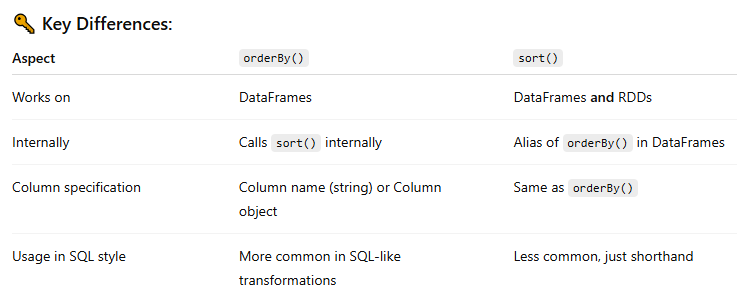

In [ ]:
# syntax
df.orderBy('col_name')  # Ascending by default
df.orderBy(df.column_name.desc())  # Descending order

In [26]:
# Sample DataFrame
data = [("John", 28), ("Mike", 25), ("Sara", 30)]
df = spark.createDataFrame(data, ["Name", "Age"])


In [27]:
df.show()

+----+---+
|Name|Age|
+----+---+
|John| 28|
|Mike| 25|
|Sara| 30|
+----+---+



In [28]:
# Using orderBy
df.orderBy("Age").show()

# Using sort
df.sort("Age").show()

+----+---+
|Name|Age|
+----+---+
|Mike| 25|
|John| 28|
|Sara| 30|
+----+---+

+----+---+
|Name|Age|
+----+---+
|Mike| 25|
|John| 28|
|Sara| 30|
+----+---+



In [30]:
df.orderBy(df.Age.desc()).show()

+----+---+
|Name|Age|
+----+---+
|Sara| 30|
|John| 28|
|Mike| 25|
+----+---+



In [31]:
df.sort(df.Age.desc()).show()

+----+---+
|Name|Age|
+----+---+
|Sara| 30|
|John| 28|
|Mike| 25|
+----+---+



In [ ]:
# Sorting descending
df.orderBy(df.Age.desc()).show()
df.sort(df.Age.desc()).show()

In [ ]:
data = [
    (1, "Alice", None, 5000),
    (2, "Bob", "IT", 4000),
    (3, None, "HR", 6000)
]

df = spark.createDataFrame(data, ["id", "name", "department", "salary"])

In [ ]:
df.show()

+---+-----+----------+------+
| id| name|department|salary|
+---+-----+----------+------+
|  1|Alice|      NULL|  5000|
|  2|  Bob|        IT|  4000|
|  3| NULL|        HR|  6000|
+---+-----+----------+------+



In [ ]:
df.orderBy("salary").show()

+---+-----+----------+------+
| id| name|department|salary|
+---+-----+----------+------+
|  2|  Bob|        IT|  4000|
|  1|Alice|      NULL|  5000|
|  3| NULL|        HR|  6000|
+---+-----+----------+------+



In [ ]:
df.orderBy(df.salary.desc()).show()

+---+-----+----------+------+
| id| name|department|salary|
+---+-----+----------+------+
|  3| NULL|        HR|  6000|
|  1|Alice|      NULL|  5000|
|  2|  Bob|        IT|  4000|
+---+-----+----------+------+



In [ ]:
# example
df.orderBy("salary").show()  # Ascending order
df.orderBy(df.age.desc()).show()  # Descending order

✅ Key Takeaways:

By default, orderBy() sorts in ascending order.

To sort in descending order, use .desc().

### Reading CSV file

In [32]:
df = spark.read.csv('/content/employees.csv')
df.show()

+------+-------+----------+------+---+-------------+
|   _c0|    _c1|       _c2|   _c3|_c4|          _c5|
+------+-------+----------+------+---+-------------+
|emp_id|   name|department|salary|age|         city|
|   101|  Alice|        HR| 50000| 30|     New York|
|   102|    Bob|        IT| 60000| 32|San Francisco|
|   103|Charlie|        HR| 55000| 29|      Chicago|
|   104|  David|        IT| 75000| 35|       Austin|
|   105|    Eve|   Finance| 80000| 40|      Seattle|
|   106|  Frank|   Finance| 40000| 28|       Boston|
|   107|  Grace|        HR| 60000| 33|       Denver|
+------+-------+----------+------+---+-------------+



In [33]:
df = spark.read.csv("/content/employees.csv", header=True)
df.show()

+------+-------+----------+------+---+-------------+
|emp_id|   name|department|salary|age|         city|
+------+-------+----------+------+---+-------------+
|   101|  Alice|        HR| 50000| 30|     New York|
|   102|    Bob|        IT| 60000| 32|San Francisco|
|   103|Charlie|        HR| 55000| 29|      Chicago|
|   104|  David|        IT| 75000| 35|       Austin|
|   105|    Eve|   Finance| 80000| 40|      Seattle|
|   106|  Frank|   Finance| 40000| 28|       Boston|
|   107|  Grace|        HR| 60000| 33|       Denver|
+------+-------+----------+------+---+-------------+



In [34]:
df.printSchema()

root
 |-- emp_id: string (nullable = true)
 |-- name: string (nullable = true)
 |-- department: string (nullable = true)
 |-- salary: string (nullable = true)
 |-- age: string (nullable = true)
 |-- city: string (nullable = true)



In [35]:
df.describe()

DataFrame[summary: string, emp_id: string, name: string, department: string, salary: string, age: string, city: string]

In [ ]:
df2 = spark.read.csv('/content/employees.csv', header = True)
df2.show()

+------+-------+----------+------+---+-------------+
|emp_id|   name|department|salary|age|         city|
+------+-------+----------+------+---+-------------+
|   101|  Alice|        HR| 50000| 30|     New York|
|   102|    Bob|        IT| 60000| 32|San Francisco|
|   103|Charlie|        HR| 55000| 29|      Chicago|
|   104|  David|        IT| 75000| 35|       Austin|
|   105|    Eve|   Finance| 80000| 40|      Seattle|
|   106|  Frank|   Finance| 40000| 28|       Boston|
|   107|  Grace|        HR| 60000| 33|       Denver|
+------+-------+----------+------+---+-------------+



In [ ]:
df3 = spark.read.csv('/content/employees.csv', header = True, inferSchema=True)
df3.show()

+------+-------+----------+------+---+-------------+
|emp_id|   name|department|salary|age|         city|
+------+-------+----------+------+---+-------------+
|   101|  Alice|        HR| 50000| 30|     New York|
|   102|    Bob|        IT| 60000| 32|San Francisco|
|   103|Charlie|        HR| 55000| 29|      Chicago|
|   104|  David|        IT| 75000| 35|       Austin|
|   105|    Eve|   Finance| 80000| 40|      Seattle|
|   106|  Frank|   Finance| 40000| 28|       Boston|
|   107|  Grace|        HR| 60000| 33|       Denver|
+------+-------+----------+------+---+-------------+



In [ ]:
df3.printSchema()

root
 |-- emp_id: integer (nullable = true)
 |-- name: string (nullable = true)
 |-- department: string (nullable = true)
 |-- salary: integer (nullable = true)
 |-- age: integer (nullable = true)
 |-- city: string (nullable = true)



In [ ]:
df_csv = spark.read.csv("data/employees.csv", header=True, inferSchema=True)
df_csv.show()


✅ Key Takeaways:

header=True → Uses the first row as column names.

inferSchema=True → Automatically detects data types.

### Reading JSON file

In [ ]:
# Read JSON file
df = spark.read.json("/content/employees.json")

# Display schema and data
df.printSchema()
df.show()

✅ Key Takeaways:

JSON is semi-structured, and Spark automatically detects the schema.

### Reading parquet file

In [ ]:
df_parquet = spark.read.parquet("data/employees.parquet")
df_parquet.show()

✅ Key Takeaways:

Parquet is faster and optimized for big data due to columnar storage.

Preferred format for storing large datasets in data lakes.

In [ ]:
#excel

In [ ]:
df_excel = spark.read.format("com.crealytics.spark.excel") \
    .option("header", "true") \
    .option("inferSchema", "true") \
    .load("marks.xlsx")

df_excel.show()


In [ ]:
# text
df_text = spark.read.text("notes.txt")
df_text.show(truncate=False)


### create spark dataframe from pandas dataframe

Useful when working with small datasets in Pandas before moving to Spark.

Allows seamless integration between Pandas and PySpark.

In [ ]:
import pandas as pd
from pyspark.sql import SparkSession

spark = SparkSession.builder.appName("PandasToSpark").getOrCreate()

pandas_df = pd.DataFrame({"id": [1, 2], "name": ["Alice", "Bob"], "age": [25, 30]}) # pandas dataframe

# now create spark dataframe from pandas
spark_df = spark.createDataFrame(pandas_df)

spark_df.show()


✅ Key Takeaways:

Use createDataFrame(pandas_df) to convert Pandas → PySpark.

This helps when transitioning from small to big data processing.